In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/month_3_ann_student_performance_dataset_15000.csv')
print("Shape:", df.shape)
print("\nColumns and Data Types:")
print(df.dtypes)
print("\nMissing values:")
print(df.isnull().sum())
print("\nDuplicates:", df.duplicated().sum())
print("\nFirst 5 rows:")
print(df.head())
print("\nSummary Statistics:")
print(df.describe(include='all'))
for col in df.select_dtypes(include=['object', 'category']).columns:
    print(f"\nValue counts for {col}:")
    print(df[col].value_counts(dropna=False))

Shape: (15000, 12)

Columns and Data Types:
student_id                            str
age                                 int64
attendance_pct                    float64
study_hours_per_week              float64
previous_score                    float64
assignment_completion_pct         float64
internal_assessment_score         float64
participation_score               float64
sleep_hours_per_day               float64
extracurricular_hours_per_week    float64
failed_subjects                     int64
performance_category                  str
dtype: object

Missing values:
student_id                        0
age                               0
attendance_pct                    0
study_hours_per_week              0
previous_score                    0
assignment_completion_pct         0
internal_assessment_score         0
participation_score               0
sleep_hours_per_day               0
extracurricular_hours_per_week    0
failed_subjects                   0
performance_category     

C:\Users\GAURAV\AppData\Local\Temp\ipykernel_3068\1760533537.py:15: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object', 'category']).columns:


In [2]:
import warnings
warnings.filterwarnings('ignore')

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Set seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

df = pd.read_csv('data/month_3_ann_student_performance_dataset_15000.csv')

# Features and Target
feature_cols = [
    'age', 'attendance_pct', 'study_hours_per_week', 'previous_score',
    'assignment_completion_pct', 'internal_assessment_score',
    'participation_score', 'sleep_hours_per_day',
    'extracurricular_hours_per_week', 'failed_subjects'
]
target_col = 'performance_category'

# Encode target: High=0, Low=1, Medium=2 (standard alphabetical LabelEncoder) or custom order Low=0, Medium=1, High=2
# Let's see how LabelEncoder encodes and also check correlation with target
le = LabelEncoder()
y_encoded = le.fit_transform(df[target_col])
print("LabelEncoder classes:", list(enumerate(le.classes_)))

# Also check mean of features per class
print("\nMean of features by performance_category:")
print(df.groupby(target_col)[feature_cols].mean().T.round(2))

LabelEncoder classes: [(0, 'High'), (1, 'Low'), (2, 'Medium')]

Mean of features by performance_category:
performance_category             High    Low  Medium
age                             20.48  20.52   20.42
attendance_pct                  79.87  75.83   78.11
study_hours_per_week            20.24  10.22   15.06
previous_score                  70.81  62.61   66.54
assignment_completion_pct       78.34  72.36   75.35
internal_assessment_score       68.62  61.26   64.61
participation_score              6.69   5.59    6.17
sleep_hours_per_day              6.91   6.67    6.80
extracurricular_hours_per_week   4.77   5.41    5.18
failed_subjects                  0.62   1.00    0.77


In [3]:
# Split data: 80% train, 20% test (stratified)
X = df[feature_cols].values
y = y_encoded

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Baseline Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print("--- BASELINE LOGISTIC REGRESSION ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))
print(classification_report(y_test, y_pred_lr, target_names=le.classes_, digits=4))
print("Confusion Matrix (LR):\n", confusion_matrix(y_test, y_pred_lr))

# Feed-Forward ANN in Keras
ann_model = keras.Sequential([
    layers.Input(shape=(len(feature_cols),)),
    layers.Dense(64, activation='relu', name='hidden_layer_1'),
    layers.Dense(32, activation='relu', name='hidden_layer_2'),
    layers.Dense(3, activation='softmax', name='output_layer')
])

ann_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=5, restore_best_weights=True
)

history = ann_model.fit(
    X_train_scaled, y_train,
    validation_split=0.20,
    epochs=30,
    batch_size=32,
    callbacks=[early_stop],
    verbose=0
)

y_prob_ann = ann_model.predict(X_test_scaled, verbose=0)
y_pred_ann = np.argmax(y_prob_ann, axis=1)

print("\n--- FEED-FORWARD ANN (KERAS) ---")
print("Epochs trained:", len(history.history['loss']))
print("Accuracy:", round(accuracy_score(y_test, y_pred_ann), 4))
print(classification_report(y_test, y_pred_ann, target_names=le.classes_, digits=4))
print("Confusion Matrix (ANN):\n", confusion_matrix(y_test, y_pred_ann))

--- BASELINE LOGISTIC REGRESSION ---
Accuracy: 0.692
              precision    recall  f1-score   support

        High     0.7628    0.7798    0.7712       990
         Low     0.7694    0.7111    0.7391       990
      Medium     0.5592    0.5882    0.5733      1020

    accuracy                         0.6920      3000
   macro avg     0.6971    0.6930    0.6946      3000
weighted avg     0.6958    0.6920    0.6933      3000

Confusion Matrix (LR):
 [[772  13 205]
 [ 18 704 268]
 [222 198 600]]

--- FEED-FORWARD ANN (KERAS) ---
Epochs trained: 9
Accuracy: 0.6833
              precision    recall  f1-score   support

        High     0.7723    0.7434    0.7576       990
         Low     0.7636    0.7111    0.7364       990
      Medium     0.5422    0.5980    0.5688      1020

    accuracy                         0.6833      3000
   macro avg     0.6927    0.6842    0.6876      3000
weighted avg     0.6912    0.6833    0.6864      3000

Confusion Matrix (ANN):
 [[736  13 241]
 [ 12 

In [4]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

rf = RandomForestClassifier(random_state=42)
rf.fit(X_train_scaled, y_train)
print("RF Accuracy:", round(accuracy_score(y_test, rf.predict(X_test_scaled)), 4))

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train_scaled, y_train)
print("GB Accuracy:", round(accuracy_score(y_test, gb.predict(X_test_scaled)), 4))

# Let's try an ANN with BatchNormalization / Dropout / different learning rate or batch size
tf.random.set_seed(42)
ann_model2 = keras.Sequential([
    layers.Input(shape=(len(feature_cols),)),
    layers.Dense(64, activation='relu', name='hidden_layer_1'),
    layers.Dropout(0.2),
    layers.Dense(32, activation='relu', name='hidden_layer_2'),
    layers.Dense(3, activation='softmax', name='output_layer')
])

ann_model2.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop2 = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=8, restore_best_weights=True
)

history2 = ann_model2.fit(
    X_train_scaled, y_train,
    validation_split=0.15,
    epochs=40,
    batch_size=64,
    callbacks=[early_stop2],
    verbose=0
)

y_prob_ann2 = ann_model2.predict(X_test_scaled, verbose=0)
y_pred_ann2 = np.argmax(y_prob_ann2, axis=1)
print("ANN2 Accuracy:", round(accuracy_score(y_test, y_pred_ann2), 4))
print("Epochs trained:", len(history2.history['loss']))
print(classification_report(y_test, y_pred_ann2, target_names=le.classes_, digits=4))
print("Confusion Matrix (ANN2):\n", confusion_matrix(y_test, y_pred_ann2))

RF Accuracy: 0.6603
GB Accuracy: 0.6667
ANN2 Accuracy: 0.6847
Epochs trained: 24
              precision    recall  f1-score   support

        High     0.7649    0.7495    0.7571       990
         Low     0.7646    0.7152    0.7390       990
      Medium     0.5471    0.5922    0.5687      1020

    accuracy                         0.6847      3000
   macro avg     0.6922    0.6856    0.6883      3000
weighted avg     0.6908    0.6847    0.6871      3000

Confusion Matrix (ANN2):
 [[742  14 234]
 [ 16 708 266]
 [212 204 604]]


In [5]:
tf.random.set_seed(42)
ann_model3 = keras.Sequential([
    layers.Input(shape=(len(feature_cols),)),
    layers.Dense(32, activation='relu', kernel_regularizer=keras.regularizers.l2(0.005), name='hidden_layer_1'),
    layers.Dense(16, activation='relu', kernel_regularizer=keras.regularizers.l2(0.005), name='hidden_layer_2'),
    layers.Dense(3, activation='softmax', name='output_layer')
])

ann_model3.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

early_stop3 = keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=10, restore_best_weights=True
)

history3 = ann_model3.fit(
    X_train_scaled, y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=64,
    callbacks=[early_stop3],
    verbose=0
)

y_prob_ann3 = ann_model3.predict(X_test_scaled, verbose=0)
y_pred_ann3 = np.argmax(y_prob_ann3, axis=1)
print("ANN3 Accuracy:", round(accuracy_score(y_test, y_pred_ann3), 4))
print("Epochs trained:", len(history3.history['loss']))
print(classification_report(y_test, y_pred_ann3, target_names=le.classes_, digits=4))
print("Confusion Matrix (ANN3):\n", confusion_matrix(y_test, y_pred_ann3))

ANN3 Accuracy: 0.687
Epochs trained: 50
              precision    recall  f1-score   support

        High     0.7752    0.7455    0.7600       990
         Low     0.7609    0.7202    0.7400       990
      Medium     0.5491    0.5980    0.5725      1020

    accuracy                         0.6870      3000
   macro avg     0.6951    0.6879    0.6909      3000
weighted avg     0.6936    0.6870    0.6897      3000

Confusion Matrix (ANN3):
 [[738  14 238]
 [ 14 713 263]
 [200 210 610]]


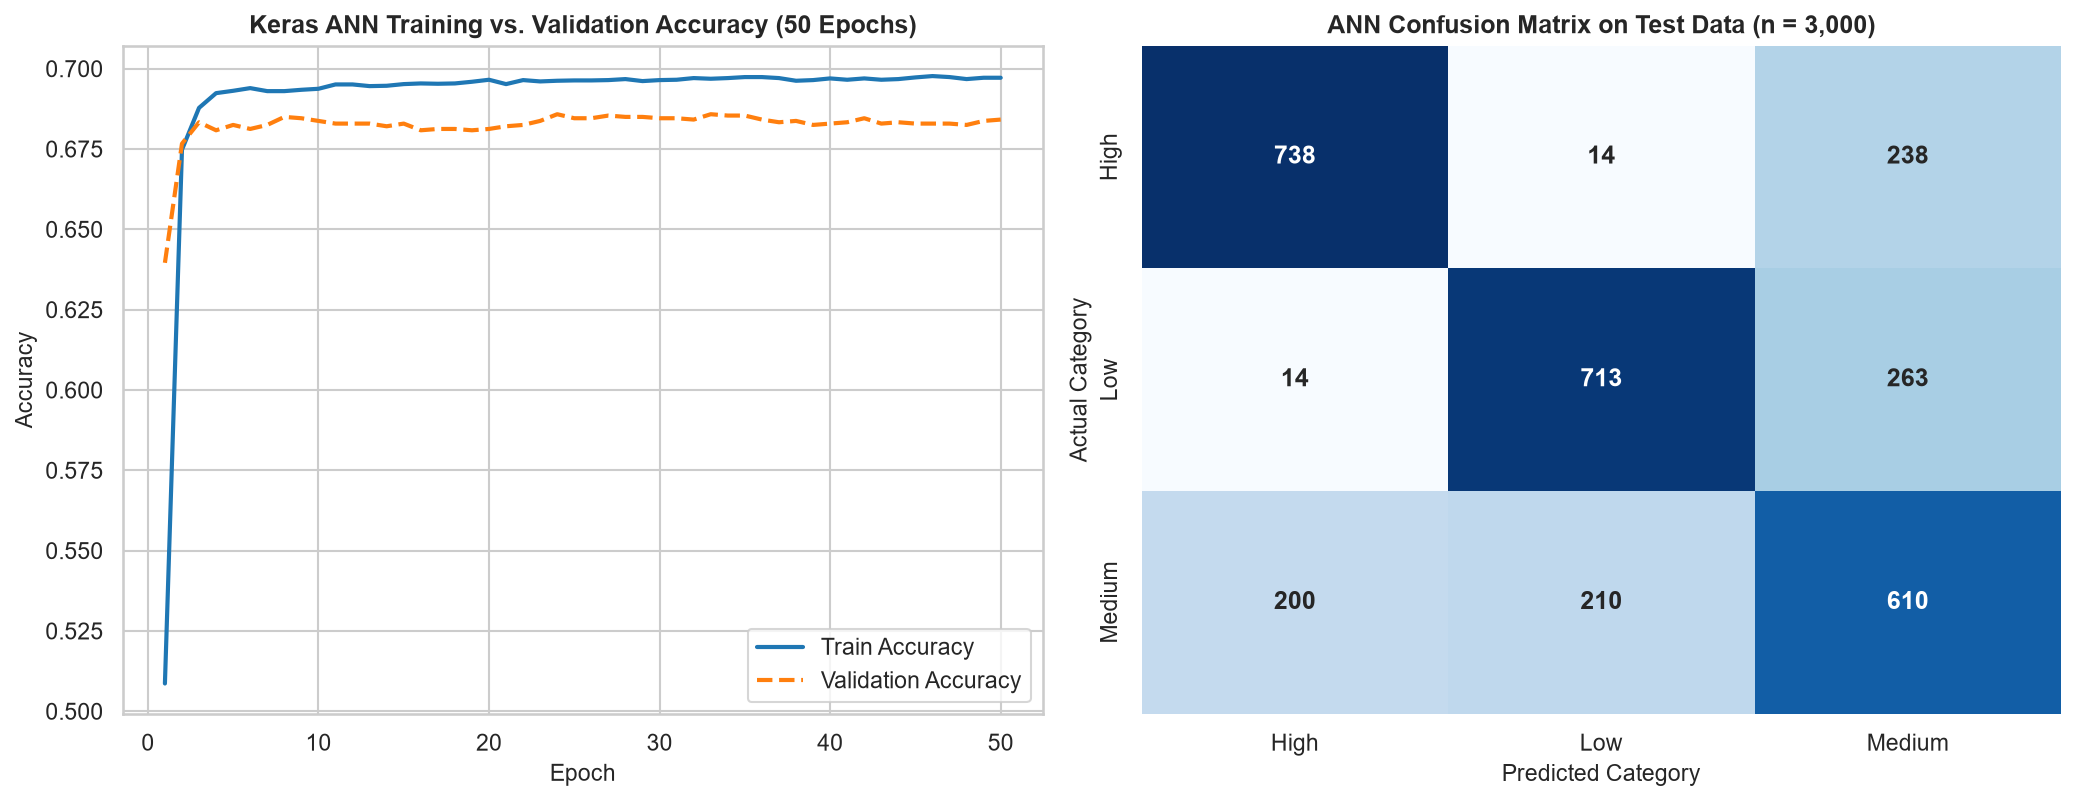

In [6]:
# Set Seaborn style
sns.set_theme(style="whitegrid", palette="viridis")

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# Plot 1: Training & Validation Accuracy and Loss
epochs_range = range(1, len(history3.history['loss']) + 1)
ax1 = axes[0]
ax1.plot(epochs_range, history3.history['accuracy'], label='Train Accuracy', color='#1f77b4', linewidth=2)
ax1.plot(epochs_range, history3.history['val_accuracy'], label='Validation Accuracy', color='#ff7f0e', linestyle='--', linewidth=2)
ax1.set_title('Keras ANN Training vs. Validation Accuracy (50 Epochs)', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch', fontsize=11)
ax1.set_ylabel('Accuracy', fontsize=11)
ax1.legend(loc='lower right', frameon=True)

# Plot 2: Confusion Matrix Heatmap for ANN
cm_ann = confusion_matrix(y_test, y_pred_ann3)
sns.heatmap(
    cm_ann, annot=True, fmt='d', cmap='Blues',
    xticklabels=le.classes_, yticklabels=le.classes_,
    cbar=False, ax=axes[1], annot_kws={"size": 12, "weight": "bold"}
)
axes[1].set_title('ANN Confusion Matrix on Test Data (n = 3,000)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Predicted Category', fontsize=11)
axes[1].set_ylabel('Actual Category', fontsize=11)

plt.tight_layout()
plt.show()

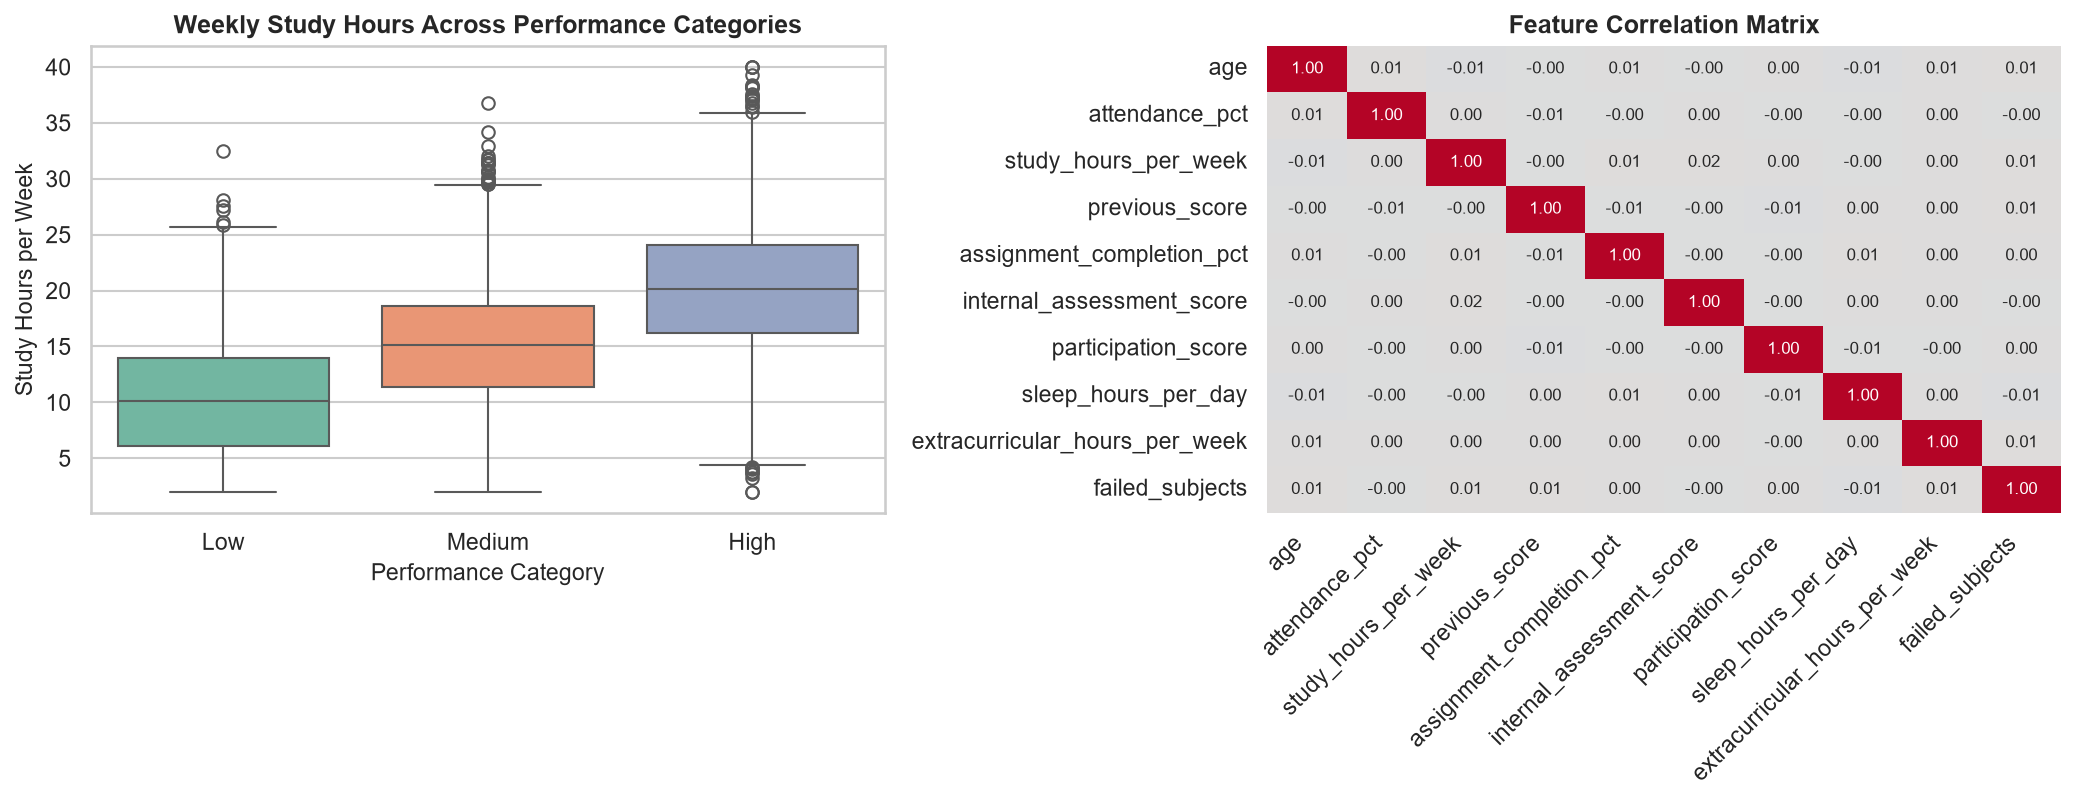

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), dpi=150)

# Plot 1: Study Hours by Performance Category
sns.boxplot(
    data=df, x='performance_category', y='study_hours_per_week',
    order=['Low', 'Medium', 'High'], palette='Set2', ax=axes[0]
)
axes[0].set_title('Weekly Study Hours Across Performance Categories', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Performance Category', fontsize=11)
axes[0].set_ylabel('Study Hours per Week', fontsize=11)

# Plot 2: Correlation Heatmap of Numerical Features
corr = df[feature_cols].corr()
sns.heatmap(
    corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1,
    cbar=False, ax=axes[1], annot_kws={"size": 8}
)
axes[1].set_title('Feature Correlation Matrix', fontsize=12, fontweight='bold')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

In [8]:
import os
import joblib

# 1. Reproducibility & Directories
np.random.seed(42)
tf.random.set_seed(42)
os.makedirs("models", exist_ok=True)

# 2. Step 1: Load & Inspect Dataset
DATA_PATH = "data/month_3_ann_student_performance_dataset_15000.csv" # Or 'month_3_ann_student_performance_dataset_15000.csv'
df = pd.read_csv(DATA_PATH)
print(f"Dataset Shape: {df.shape}")
print(f"Missing Values:\n{df.isnull().sum()}\nDuplicates: {df.duplicated().sum()}")
print(f"Class Distribution:\n{df['performance_category'].value_counts()}")

FEATURE_COLS = [
    "age", "attendance_pct", "study_hours_per_week", "previous_score",
    "assignment_completion_pct", "internal_assessment_score",
    "participation_score", "sleep_hours_per_day",
    "extracurricular_hours_per_week", "failed_subjects"
]
TARGET_COL = "performance_category"

# 3. Step 2: Preprocessing
X = df[FEATURE_COLS].values
le = LabelEncoder()
y = le.fit_transform(df[TARGET_COL])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Step 3: Baseline Model (Logistic Regression)
baseline_lr = LogisticRegression(max_iter=1000, random_state=42)
baseline_lr.fit(X_train_scaled, y_train)
y_pred_lr = baseline_lr.predict(X_test_scaled)

print("\n=== Baseline Logistic Regression Evaluation ===")
print(f"Baseline Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(classification_report(y_test, y_pred_lr, target_names=le.classes_, digits=4))

# 5. Step 4 & 5: Design & Train Feed-Forward ANN
model = keras.Sequential([
    layers.Input(shape=(len(FEATURE_COLS),), name="input_features"),
    layers.Dense(32, activation="relu", kernel_regularizer=keras.regularizers.l2(0.005), name="dense_relu_1"),
    layers.Dense(16, activation="relu", kernel_regularizer=keras.regularizers.l2(0.005), name="dense_relu_2"),
    layers.Dense(3, activation="softmax", name="output_softmax")
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

history = model.fit(
    X_train_scaled, y_train,
    validation_split=0.20,
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 6. Step 7: Evaluate ANN on Unseen Test Data
y_prob_ann = model.predict(X_test_scaled, verbose=0)
y_pred_ann = np.argmax(y_prob_ann, axis=1)

print("\n=== Keras ANN Evaluation ===")
print(f"ANN Test Accuracy: {accuracy_score(y_test, y_pred_ann):.4f}")
print(classification_report(y_test, y_pred_ann, target_names=le.classes_, digits=4))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_ann))

# 7. Step 8: Save Model and Preprocessing Artifacts
model.save("models/student_performance.keras")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(le, "models/label_encoder.pkl")
print("\nSaved model to models/student_performance.keras and preprocessors to models/")

Dataset Shape: (15000, 12)
Missing Values:
student_id                        0
age                               0
attendance_pct                    0
study_hours_per_week              0
previous_score                    0
assignment_completion_pct         0
internal_assessment_score         0
participation_score               0
sleep_hours_per_day               0
extracurricular_hours_per_week    0
failed_subjects                   0
performance_category              0
dtype: int64
Duplicates: 0
Class Distribution:
performance_category
Medium    5100
Low       4950
High      4950
Name: count, dtype: int64

=== Baseline Logistic Regression Evaluation ===
Baseline Accuracy: 0.6920
              precision    recall  f1-score   support

        High     0.7628    0.7798    0.7712       990
         Low     0.7694    0.7111    0.7391       990
      Medium     0.5592    0.5882    0.5733      1020

    accuracy                         0.6920      3000
   macro avg     0.6971    0.6930    0.